In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

In [2]:
def process_video_ppg(video_path, output_dir, amp_factor=15, duration=3, target_fps=30):
    os.makedirs(output_dir, exist_ok=True)
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"오류: '{video_path}' 비디오를 열 수 없습니다. 경로를 확인해주세요.")
        return

    original_fps = cap.get(cv2.CAP_PROP_FPS)
    if original_fps == 0 or np.isnan(original_fps):
        original_fps = 30
        
    print(f"▶ 원본 비디오 FPS: {original_fps:.2f}")
    
    frame_count = 0
    saved_count = 0
    target_frames = duration * target_fps
    
    last_face_box = None
    sample_img = None
    
    while cap.isOpened() and saved_count < target_frames:
        ret, frame = cap.read()
        if not ret:
            break
            
        expected_frame_idx = int(saved_count * (original_fps / target_fps))
        
        if frame_count == expected_frame_idx:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3, minSize=(50, 50))
            
            if len(faces) > 0:
                faces = sorted(faces, key=lambda f: f[2]*f[3], reverse=True)
                last_face_box = faces[0]
            elif last_face_box is None:
                h, w = frame.shape[:2]
                box_size = min(h, w) // 2
                last_face_box = (w//2 - box_size//2, h//2 - box_size//2, box_size, box_size)
                
            if last_face_box is not None:
                x, y, w, h = last_face_box
                x, y = max(0, x), max(0, y)
                w = min(w, frame.shape[1] - x)
                h = min(h, frame.shape[0] - y)
                
                face_crop = frame[y:y+h, x:x+w]
                
                ycbcr = cv2.cvtColor(face_crop, cv2.COLOR_BGR2YCrCb)
                y_ch, cr_ch, cb_ch = cv2.split(ycbcr)
                
                cr_amp = np.clip((cr_ch.astype(np.float32) - 128.0) * amp_factor + 128.0, 0, 255).astype(np.uint8)
                cb_amp = np.clip((cb_ch.astype(np.float32) - 128.0) * amp_factor + 128.0, 0, 255).astype(np.uint8)
                
                ycbcr_amp = cv2.merge([y_ch, cr_amp, cb_amp])
                result_bgr = cv2.cvtColor(ycbcr_amp, cv2.COLOR_YCrCb2BGR)
                
                output_path = os.path.join(output_dir, f"frame_{saved_count:04d}.jpg")
                
                # 🚨 핵심 수정 부분: 한글 경로에서도 사진이 강제로 저장되도록 우회 처리 🚨
                # cv2.imwrite 대신 np.tofile 을 사용하여 한글 경로 버그 완벽 해결
                is_success, im_buf_arr = cv2.imencode(".jpg", result_bgr)
                if is_success:
                    im_buf_arr.tofile(output_path)
                
                if saved_count == 0:
                    sample_img = cv2.cvtColor(result_bgr, cv2.COLOR_BGR2RGB)
                    
                saved_count += 1
                
        frame_count += 1

    cap.release()
    print(f"▶ 전처리 완료! 총 {saved_count}장의 이미지가 '{output_dir}'에 저장되었습니다.")
    
    if sample_img is not None:
        plt.figure(figsize=(6, 6))
        plt.imshow(sample_img)
        plt.title(f"Processed Sample (Amp: {amp_factor}x)")
        plt.axis('off')
        plt.show()

▶ 원본 비디오 FPS: 30.10
▶ 전처리 완료! 총 90장의 이미지가 'ppg_preprocessed/DeepFake_Real_1/CbCr_x15'에 저장되었습니다.


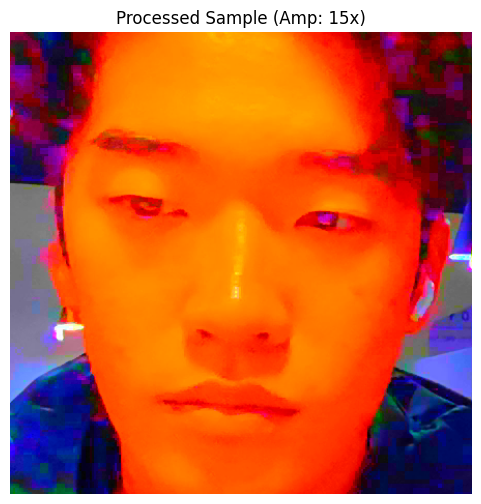

In [4]:
VIDEO_FILE = "DeepFake_Real_1.mp4"

video_name = os.path.splitext(os.path.basename(VIDEO_FILE))[0]
OUTPUT_FOLDER = f"ppg_preprocessed/{video_name}/CbCr_x15"

process_video_ppg(VIDEO_FILE, OUTPUT_FOLDER, amp_factor=15, duration=3, target_fps=30)